# Lab 4 – Decision Tree Classification

## Step 1: Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, GridSearchCV, cross_val_score,
    learning_curve, validation_curve
)

from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix,
    roc_curve, auc
)

from sklearn.preprocessing import label_binarize

## Step 2: Load the Dataset

In [2]:
df = pd.read_csv("WineQT.csv")

# Display first and last five records
print("First 5 Records:")
print(df.head())

print("\nLast 5 Records:")
print(df.tail())

# Dataset Shape
print("\nDataset Shape:")
print(df.shape)

# Column Names
print("\nColumns:")
print(df.columns)

# Dataset Information
print("\nDataset Information:")
print(df.info())

# Statistical Summary
print("\nStatistical Summary:")
print(df.describe())

First 5 Records:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  Id  
0      9.4        5   0  
1      9.8       

## Step 3: Check Missing Values

In [3]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64


## Step 4: Check Duplicate Records

In [4]:
print("\nDuplicate Records:")
print(df.duplicated().sum())


Duplicate Records:
0


## Step 5: Data Preparation

In [5]:
# Remove ID column if it is present
df = df.drop(columns=["Id"], errors="ignore")

pd.set_option("display.float_format", "{:.2f}".format)

## Step 6: Univariate Analysis

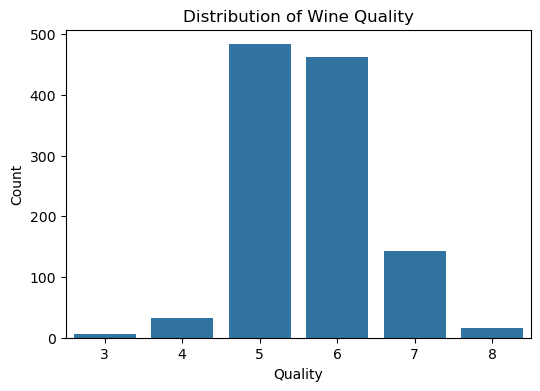

In [6]:
plt.figure(figsize=(6,4))

sns.countplot(x="quality", data=df)

plt.title("Distribution of Wine Quality")
plt.xlabel("Quality")
plt.ylabel("Count")

plt.show()

## Step 7: Multivariate Analysis

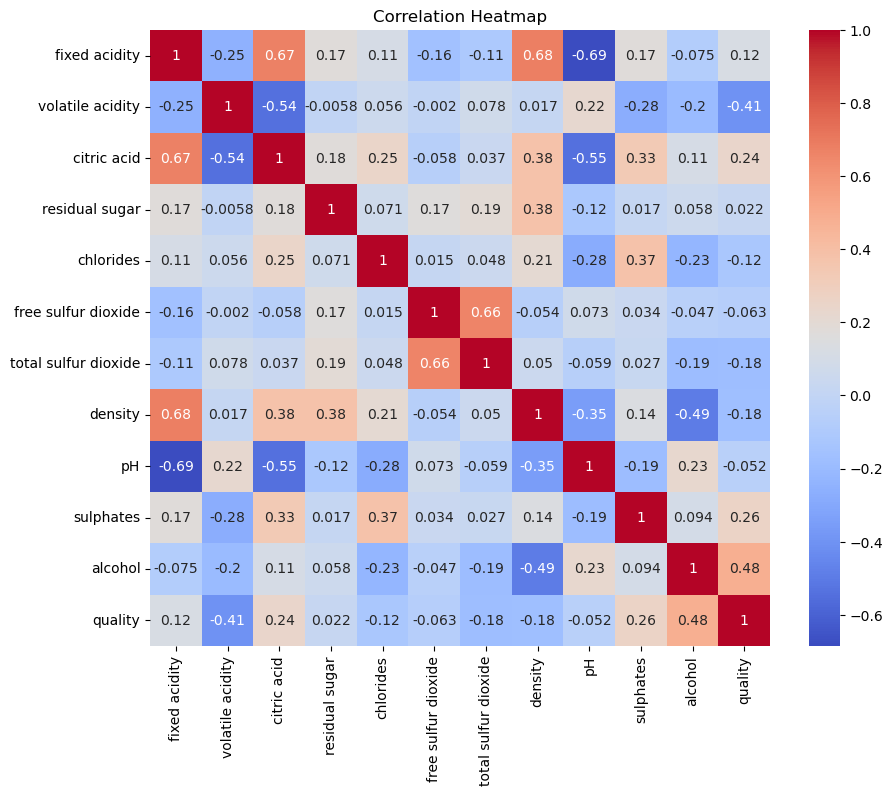

In [7]:
plt.figure(figsize=(10,8))

numeric_df = df.select_dtypes(include=["number"])

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

## Step 8: Prepare Training and Testing Data

In [8]:
X = df.drop("quality", axis=1)
y = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

## Step 9: Train Decision Tree Classifier

In [9]:
dt_model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

dt_model.fit(X_train, y_train)

y_train_pred = dt_model.predict(X_train)
y_test_pred = dt_model.predict(X_test)

## Step 10: Model Accuracy and Classification Report

In [10]:
train_accuracy = accuracy_score(y_train, y_train_pred)
print("Training Accuracy:", train_accuracy)

test_accuracy = accuracy_score(y_test, y_test_pred)
print("Test Accuracy:", test_accuracy)

print("Precision:",
      precision_score(y_test, y_test_pred, average="weighted"))

print("Recall:",
      recall_score(y_test, y_test_pred, average="weighted"))

print("F1 Score:",
      f1_score(y_test, y_test_pred, average="weighted"))

print(classification_report(y_test, y_test_pred))

Training Accuracy: 1.0
Test Accuracy: 0.6200873362445415
Precision: 0.6048485507129225
Recall: 0.6200873362445415
F1 Score: 0.6104277944856711
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.33      0.14      0.20         7
           5       0.71      0.76      0.74        97
           6       0.59      0.57      0.58        92
           7       0.44      0.52      0.48        29
           8       0.00      0.00      0.00         3

    accuracy                           0.62       229
   macro avg       0.35      0.33      0.33       229
weighted avg       0.60      0.62      0.61       229



## Step 11: Confusion Matrix

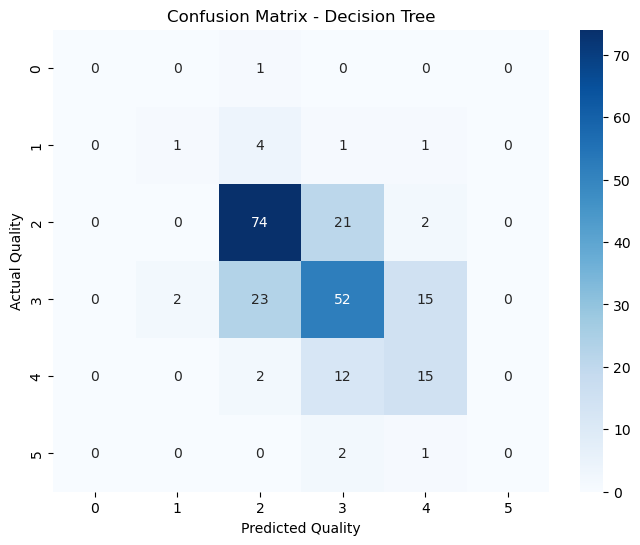

In [11]:
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted Quality")
plt.ylabel("Actual Quality")
plt.title("Confusion Matrix - Decision Tree")

plt.show()

## Step 12: Decision Tree Visualization

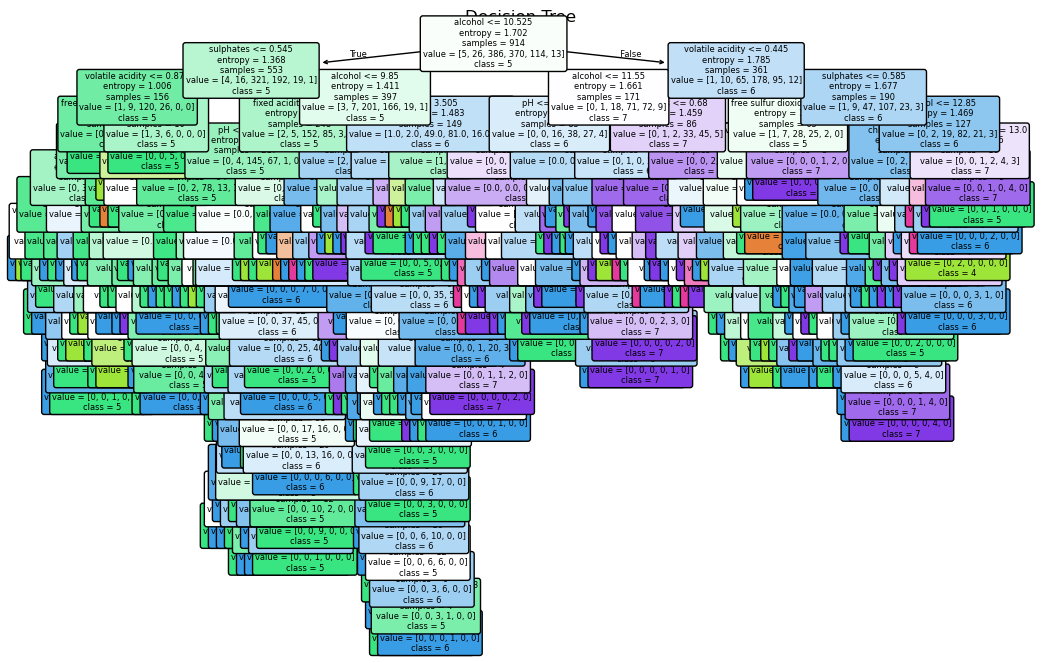

In [12]:
plt.figure(figsize=(12, 8))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=[str(c) for c in sorted(y.unique())],
    filled=True,
    rounded=True,
    fontsize=6
)

plt.title("Decision Tree")
plt.show()

## Step 13: ROC-AUC Curve

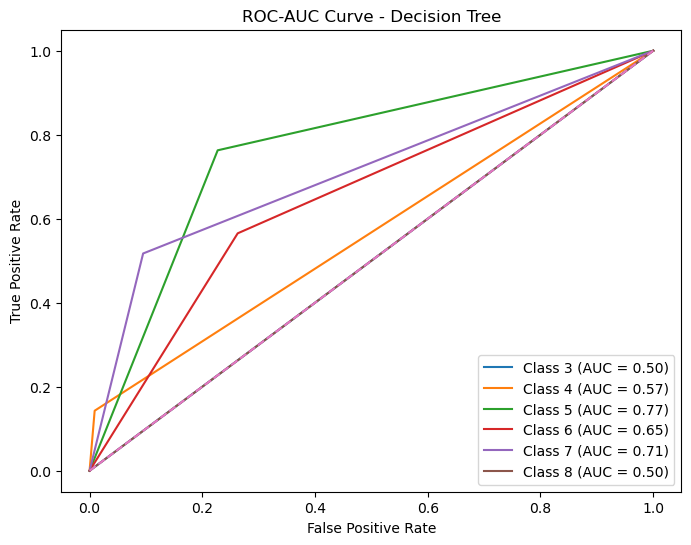

In [13]:
classes = sorted(y.unique())

y_test_bin = label_binarize(y_test, classes=classes)
y_score = dt_model.predict_proba(X_test)

plt.figure(figsize=(8, 6))

for i, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(
        fpr,
        tpr,
        label=f"Class {cls} (AUC = {roc_auc:.2f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curve - Decision Tree")
plt.legend()
plt.show()

## Step 14: Hyperparameter Tuning using GridSearchCV

In [14]:
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    scoring="accuracy",
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross Validation Score:", grid_search.best_score_)

best_model = grid_search.best_estimator_

Best Parameters: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 2}
Best Cross Validation Score: 0.5667327208310814


## Step 15: Cross-Validation

In [15]:
cv_scores = cross_val_score(
    best_model,
    X,
    y,
    cv=10,
    scoring="accuracy"
)

print("10-Fold Cross Validation Scores:")
print(cv_scores)

print("Mean CV Accuracy:", cv_scores.mean())

10-Fold Cross Validation Scores:
[0.45217391 0.5826087  0.45217391 0.54385965 0.49122807 0.57017544
 0.56140351 0.55263158 0.55263158 0.56140351]
Mean CV Accuracy: 0.5320289855072463


## Step 16: Learning Curve

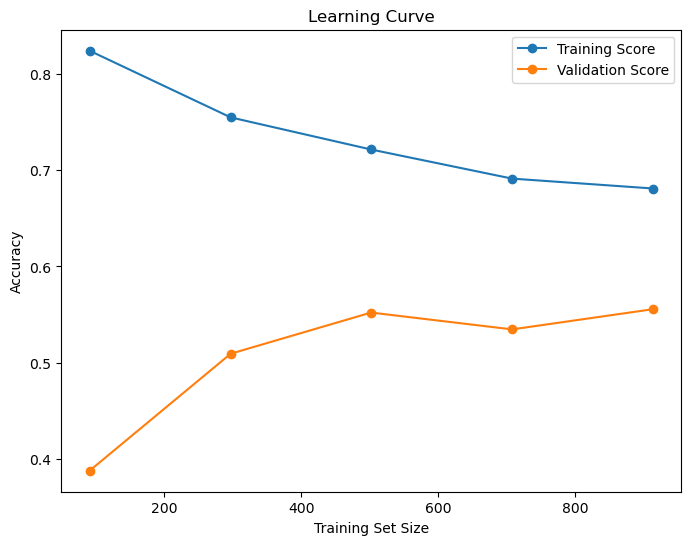

In [16]:
train_sizes, train_scores, test_scores = learning_curve(
    best_model,
    X,
    y,
    cv=5,
    scoring="accuracy",
    train_sizes=np.linspace(0.1, 1.0, 5)
)

plt.figure(figsize=(8, 6))

plt.plot(
    train_sizes,
    train_scores.mean(axis=1),
    marker="o",
    label="Training Score"
)

plt.plot(
    train_sizes,
    test_scores.mean(axis=1),
    marker="o",
    label="Validation Score"
)

plt.xlabel("Training Set Size")
plt.ylabel("Accuracy")
plt.title("Learning Curve")
plt.legend()
plt.show()

## Step 17: Validation Curve

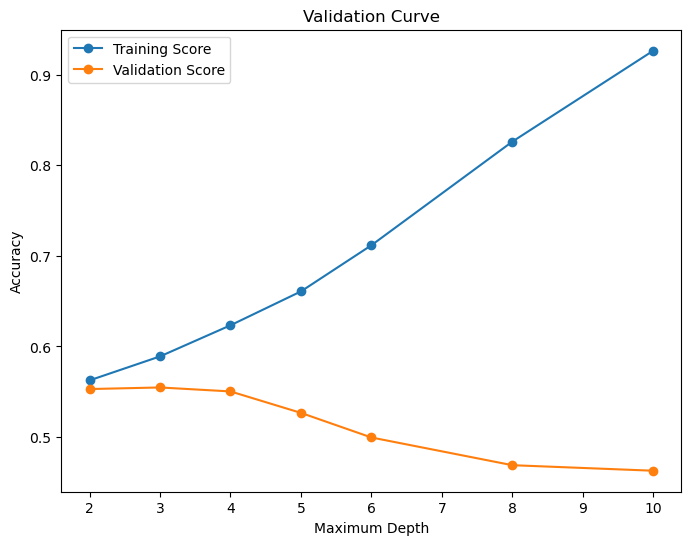

In [17]:
param_range = [2, 3, 4, 5, 6, 8, 10]

train_scores, test_scores = validation_curve(
    DecisionTreeClassifier(
        criterion="entropy",
        random_state=42
    ),
    X,
    y,
    param_name="max_depth",
    param_range=param_range,
    cv=5,
    scoring="accuracy"
)

plt.figure(figsize=(8, 6))

plt.plot(
    param_range,
    train_scores.mean(axis=1),
    marker="o",
    label="Training Score"
)

plt.plot(
    param_range,
    test_scores.mean(axis=1),
    marker="o",
    label="Validation Score"
)

plt.xlabel("Maximum Depth")
plt.ylabel("Accuracy")
plt.title("Validation Curve")
plt.legend()
plt.show()